In [ ]:
!pip install -q \
pandas \
numpy \
matplotlib \
seaborn \
scikit-learn \
mlflow \
fastapi \
uvicorn \
joblib

In [ ]:
import os
import json
import joblib
import mlflow

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report
)

In [ ]:
# from google.colab import files

# uploaded = files.upload()

In [ ]:
import pandas as pd

df = pd.read_csv("heart.csv")

df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


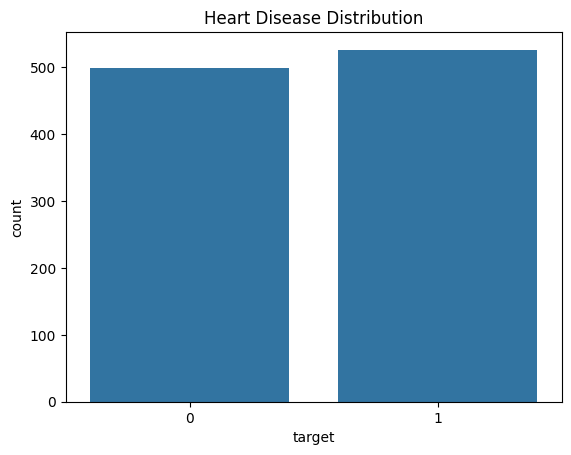

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='target', data=df)
plt.title("Heart Disease Distribution")
plt.show()

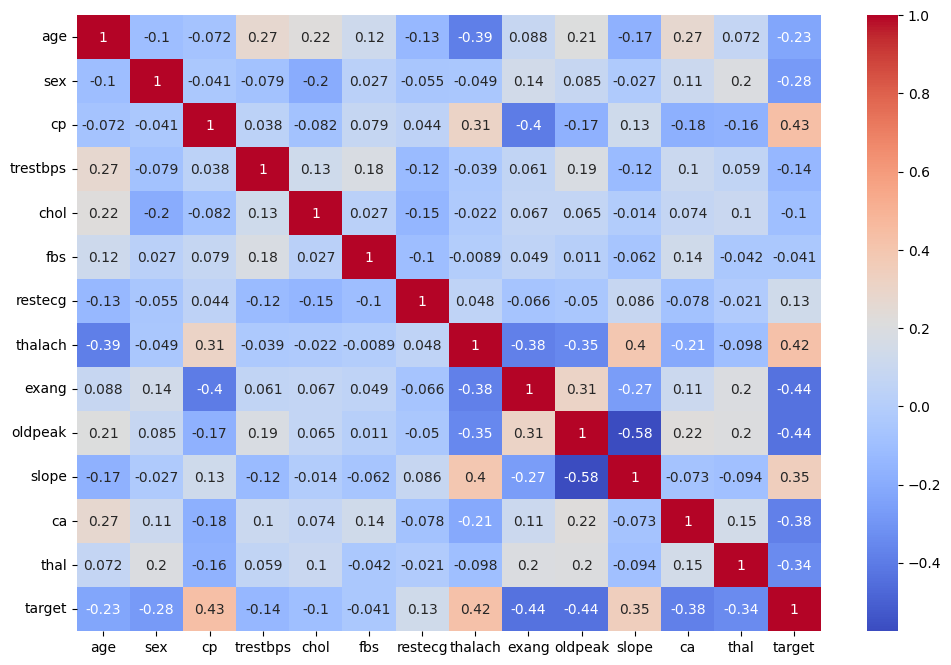

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.show()

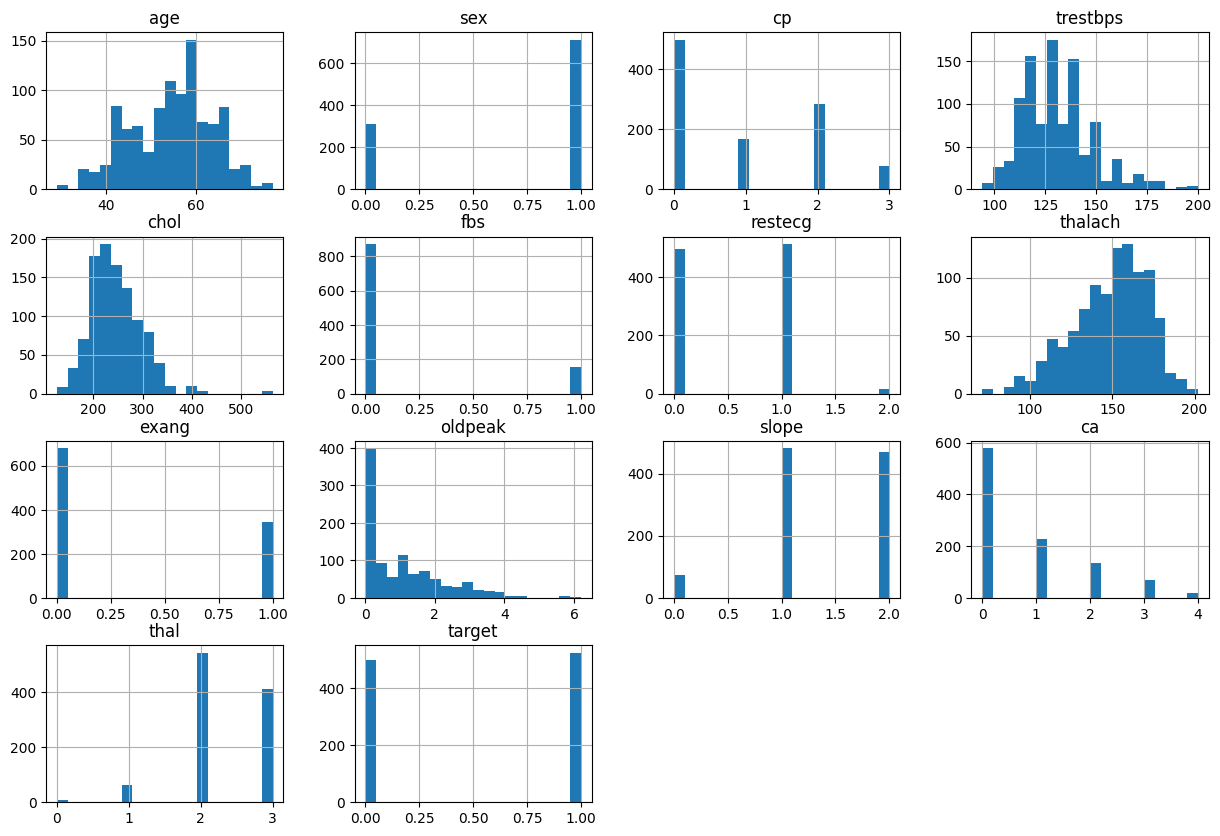

In [ ]:
df.hist(
    figsize=(15,10),
    bins=20
)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("target", axis=1)
y = df["target"]

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()

lr.fit(X_train,y_train)

LogisticRegression()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train,y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

pred = rf.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test,pred))

print("Precision:",
      precision_score(y_test,pred))

print("Recall:",
      recall_score(y_test,pred))

print(
    "ROC AUC:",
    roc_auc_score(y_test,pred)
)

Accuracy: 0.9853658536585366
Precision: 1.0
Recall: 0.970873786407767
ROC AUC: 0.9854368932038835


In [ ]:
!pip install mlflow

In [ ]:
# ==========================
# COMPLETE TRAINING PIPELINE
# ==========================

import joblib
import mlflow
import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    cross_val_score
)

from sklearn.pipeline import Pipeline

from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report
)

# --------------------------
# Feature / Target Split
# --------------------------

X = df.drop("target", axis=1)
y = df["target"]

# --------------------------
# Train Test Split
# --------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# --------------------------
# Preprocessing
# --------------------------

numeric_features = X.columns

numeric_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

preprocessor = ColumnTransformer([
    (
        "num",
        numeric_transformer,
        numeric_features
    )
])

# --------------------------
# Random Forest Pipeline
# --------------------------

rf_pipeline = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            random_state=42
        )
    )
])

# --------------------------
# Train
# --------------------------

rf_pipeline.fit(
    X_train,
    y_train
)

print("Model Training Complete")

# --------------------------
# Cross Validation
# --------------------------

cv_auc = cross_val_score(
    rf_pipeline,
    X,
    y,
    cv=5,
    scoring="roc_auc"
)

print(
    "Cross Validation ROC-AUC:",
    cv_auc.mean()
)

# --------------------------
# Prediction
# --------------------------

pred = rf_pipeline.predict(X_test)

proba = rf_pipeline.predict_proba(X_test)[:, 1]

# --------------------------
# Metrics
# --------------------------

accuracy = accuracy_score(
    y_test,
    pred
)

precision = precision_score(
    y_test,
    pred
)

recall = recall_score(
    y_test,
    pred
)

roc_auc = roc_auc_score(
    y_test,
    proba
)

print("\n===== MODEL METRICS =====")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("ROC-AUC  :", roc_auc)

print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_test,
        pred
    )
)

# --------------------------
# Save Model
# --------------------------

joblib.dump(
    rf_pipeline,
    "heart_model.pkl"
)

print("\nModel saved: heart_model.pkl")

# --------------------------
# MLflow Logging
# --------------------------

mlflow.set_tracking_uri(
    "sqlite:///mlflow.db"
)

mlflow.set_experiment(
    "HeartDiseasePrediction"
)

with mlflow.start_run():

    mlflow.log_param(
        "model",
        "RandomForest"
    )

    mlflow.log_param(
        "n_estimators",
        200
    )

    mlflow.log_param(
        "random_state",
        42
    )

    mlflow.log_metric(
        "accuracy",
        accuracy
    )

    mlflow.log_metric(
        "precision",
        precision
    )

    mlflow.log_metric(
        "recall",
        recall
    )

    mlflow.log_metric(
        "roc_auc",
        roc_auc
    )

    mlflow.log_metric(
        "cv_roc_auc",
        cv_auc.mean()
    )

    mlflow.log_artifact(
        "heart_model.pkl"
    )

print("\nMLflow logging completed successfully")

# --------------------------
# Final Summary Table
# --------------------------

results_df = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "ROC_AUC": roc_auc,
        "CV_ROC_AUC": cv_auc.mean()
    }
])

display(results_df)

Model Training Complete
Cross Validation ROC-AUC: 0.9997712978845055

===== MODEL METRICS =====
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
ROC-AUC  : 1.0

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       1.00      1.00      1.00       105

    accuracy                           1.00       205
   macro avg       1.00      1.00      1.00       205
weighted avg       1.00      1.00      1.00       205


Model saved: heart_model.pkl

MLflow logging completed successfully


,Model,Accuracy,Precision,Recall,ROC_AUC,CV_ROC_AUC
0,Random Forest,1.0,1.0,1.0,1.0,0.999771


In [ ]:
import pickle

with open(
    "heart_model.pkl",
    "wb"
) as f:
    pickle.dump(rf,f)

with open(
    "scaler.pkl",
    "wb"
) as f:
    pickle.dump(scaler,f)

In [ ]:
from fastapi import FastAPI
import pickle
import numpy as np

app = FastAPI()

model = pickle.load(
    open("heart_model.pkl","rb")
)

scaler = pickle.load(
    open("scaler.pkl","rb")
)

@app.post("/predict")
def predict(data:list):

    x = np.array(data).reshape(1,-1)

    x = scaler.transform(x)

    pred = model.predict(x)

    prob = model.predict_proba(x)

    return {
        "prediction": int(pred[0]),
        "confidence":
        float(max(prob[0]))
    }

In [ ]:
def test_prediction():

    from app.main import predict

    sample = [
        63,1,3,145,
        233,1,0,150,
        0,2.3,0,0,
        1
    ]

    result = predict(sample)

    assert "prediction" in result

In [ ]:
fastapi_code = '''
from fastapi import FastAPI
import joblib
import pandas as pd

app = FastAPI()

model = joblib.load("model.pkl")

@app.post("/predict")
def predict(data: dict):

    df = pd.DataFrame([data])

    pred = model.predict(df)[0]

    prob = model.predict_proba(df)[0].max()

    return {
        "prediction": int(pred),
        "confidence": float(prob)
    }
'''

In [ ]:
os.makedirs(
    "generated/app",
    exist_ok=True
)

with open(
    "generated/app/main.py",
    "w"
) as f:
    f.write(fastapi_code)